# Public procurement in Colombia (SECOP II)

**Objective:** analyse how the Colombian State buys: how much it contracts each year, by which modality (public tender or direct contracting), in which departments, how concentrated the suppliers are, and if the "Ley de Garantías" (law 996 of 2005, that stops direct contracting in the months before the presidential elections) is visible in the data.

**Data:** SECOP II - Contratos Electrónicos, Colombia Compra Eficiente (datos.gov.co, dataset `jbjy-vk9h`), around 5 million contracts signed between 2019 and September 2026.

Libraries of the project: `pandas`, `numpy`, `matplotlib`, `seaborn` and `requests`.

## Part 1. Libraries

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

## Part 2. Download with SoQL

The dataset is too big to download, so we use the SoQL language of the API (very similar to SQL) to do the `GROUP BY` on the server. We remove contracts with value 0 or more than 5 trillion COP, which are typing errors (more than the biggest road concessions).

In [2]:
url = "https://www.datos.gov.co/resource/jbjy-vk9h.json"
base = ("fecha_de_firma >= '2019-01-01' AND fecha_de_firma < '2026-10-01' "
        "AND valor_del_contrato > 0 AND valor_del_contrato < 5000000000000")

def consulta(nombre, select, group, where=base):
    ruta = f"data/{nombre}.csv"
    if os.path.exists(ruta):
        return pd.read_csv(ruta)
    filas, offset = [], 0
    while True:
        params = {"$select": select, "$where": where, "$group": group, "$order": group, "$limit": 50000, "$offset": offset}
        r = requests.get(url, params=params, timeout=900)
        pagina = r.json()
        filas.extend(pagina)
        if len(pagina) < 50000:
            break
        offset += 50000
        time.sleep(1)
    d = pd.DataFrame(filas)
    d.to_csv(ruta, index=False)
    return d

anio_mod = consulta("by_year_modality", "date_extract_y(fecha_de_firma) AS year, modalidad_de_contratacion AS modality, count(*) AS n, sum(valor_del_contrato) AS value", "year, modality")
mes_mod = consulta("monthly_modality", "date_trunc_ym(fecha_de_firma) AS month, modalidad_de_contratacion AS modality, orden, count(*) AS n, sum(valor_del_contrato) AS value", "month, modality, orden")
dep = consulta("by_department_2025", "departamento, orden, count(*) AS n, sum(valor_del_contrato) AS value", "departamento, orden",
               base + " AND fecha_de_firma >= '2025-01-01' AND fecha_de_firma < '2026-01-01'")
pyme = consulta("by_year_sme", "date_extract_y(fecha_de_firma) AS year, es_pyme, count(*) AS n, sum(valor_del_contrato) AS value", "year, es_pyme")
prov = consulta("suppliers_2025", "documento_proveedor, count(*) AS n, sum(valor_del_contrato) AS value", "documento_proveedor",
                base + " AND fecha_de_firma >= '2025-01-01' AND fecha_de_firma < '2026-01-01'")
for d in [anio_mod, mes_mod, dep, pyme, prov]:
    for c in ["n", "value", "year"]:
        if c in d.columns:
            d[c] = pd.to_numeric(d[c])
print("Contracts:", anio_mod["n"].sum())

Contracts: 5327434


## Part 3. How much and how does the State contract?

In [3]:
anio_mod["direct"] = anio_mod["modality"].str.contains("directa", case=False, na=False)
total = anio_mod.groupby("year")[["n", "value"]].sum()
directa = anio_mod[anio_mod["direct"]].groupby("year")[["n", "value"]].sum()
resumen = pd.DataFrame({"contracts": total["n"], "value_COP_trillion": total["value"] / 1e12,
                        "direct_%_contracts": directa["n"] / total["n"] * 100,
                        "direct_%_value": directa["value"] / total["value"] * 100})
resumen.round(1)

,contracts,value_COP_trillion,direct_%_contracts,direct_%_value
year,,,,
2019,141248,32.7,61.0,36.4
2020,352533,76.1,77.9,35.0
2021,554263,118.8,81.9,52.9
2022,703206,103.3,80.5,41.8
2023,829267,129.0,78.0,40.9
2024,875293,125.1,76.5,42.3
2025,1010406,180.9,76.5,49.9
2026,861218,99.7,80.3,45.3


The number of contracts grows every year (in part because more entities moved from SECOP I to SECOP II, so 2019-2020 are incomplete). Around 8 of every 10 contracts are direct contracting, but they are less than half of the value: they are many small contracts (mostly personal services), while public tenders are fewer and bigger. 2026 only has data until September.

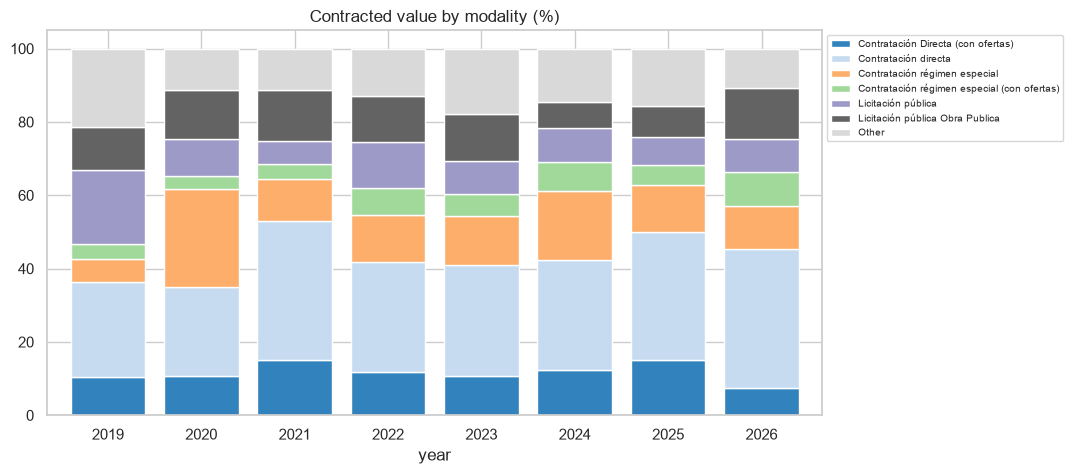

In [4]:
top = anio_mod.groupby("modality")["value"].sum().sort_values(ascending=False).index[:6]
anio_mod["mod"] = anio_mod["modality"].where(anio_mod["modality"].isin(top), "Other")
mix = anio_mod.pivot_table(index="year", columns="mod", values="value", aggfunc="sum")
mix = mix.div(mix.sum(axis=1), axis=0) * 100
mix.plot(kind="bar", stacked=True, figsize=(10, 5), colormap="tab20c", width=0.8)
plt.title("Contracted value by modality (%)")
plt.xticks(rotation=0)
plt.legend(fontsize=7, bbox_to_anchor=(1, 1))
plt.savefig("figures/modality_mix.png", bbox_inches="tight")
plt.show()

## Part 4. Ley de Garantías

Before the presidential elections (2022 and 2026) the law stops direct contracting during around 4 months. If the law works, we should see a big jump in January (entities sign everything before the restriction) and then a collapse.

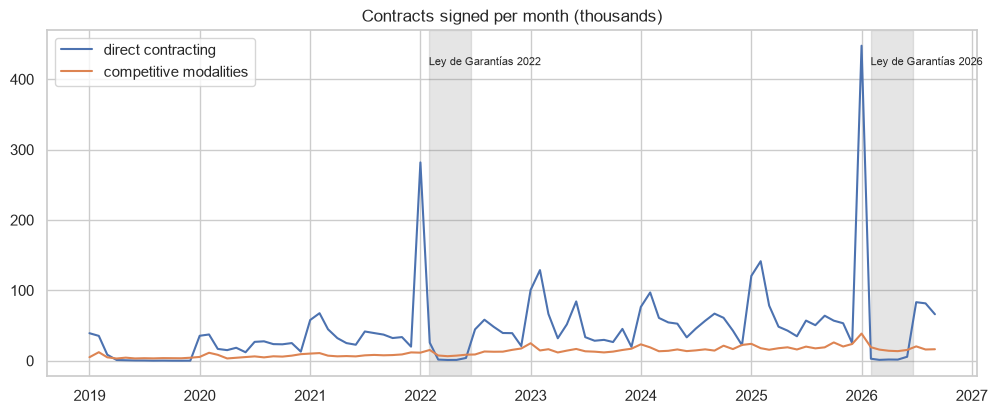

In [5]:
mes_mod["month"] = pd.to_datetime(mes_mod["month"])
mes_mod["direct"] = mes_mod["modality"].str.contains("directa", case=False, na=False)
m = mes_mod.groupby(["month", "direct"])["n"].sum().unstack()
m.columns = ["competitive", "direct"]

plt.figure(figsize=(12, 4.5))
plt.plot(m.index, m["direct"] / 1000, label="direct contracting")
plt.plot(m.index, m["competitive"] / 1000, label="competitive modalities")
for ini, fin, txt in [("2022-01-29", "2022-06-19", "Ley de Garantías 2022"), ("2026-01-31", "2026-06-21", "Ley de Garantías 2026")]:
    plt.axvspan(pd.Timestamp(ini), pd.Timestamp(fin), color="grey", alpha=0.2)
    plt.text(pd.Timestamp(ini), 420, txt, fontsize=8)
plt.title("Contracts signed per month (thousands)")
plt.legend(loc="upper left")
plt.savefig("figures/ley_garantias.png", bbox_inches="tight")
plt.show()

In [6]:
enero = m[m.index.month == 1]["direct"]
print("Direct contracts signed in January:")
print(enero.to_string())
for anio in [2021, 2022, 2023, 2025, 2026]:
    print(anio, "| average direct contracts per month February-June:", round(m.loc[f"{anio}-02":f"{anio}-06", "direct"].mean()))

Direct contracts signed in January:
month
2019-01-01     39138
2020-01-01     35470
2021-01-01     57890
2022-01-01    281784
2023-01-01    100531
2024-01-01     76446
2025-01-01    120549
2026-01-01    447596
2021 | average direct contracts per month February-June: 38458
2022 | average direct contracts per month February-June: 6716
2023 | average direct contracts per month February-June: 72640
2025 | average direct contracts per month February-June: 69155
2026 | average direct contracts per month February-June: 2639


The effect is huge. In January 2026 the State signed almost 450.000 direct contracts, and from February to June the average was only around 2.600 per month, when in a normal year it is between 40.000 and 70.000.

## Part 5. Where?

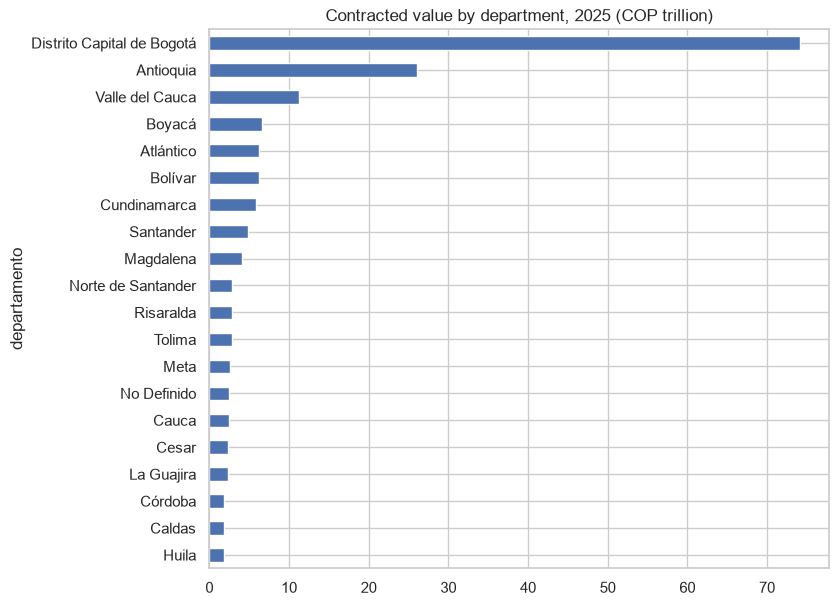

departamento
Distrito Capital de Bogotá    41.0
Antioquia                     14.4
Valle del Cauca                6.2
Boyacá                         3.7
Atlántico                      3.4
orden
Corporación Autónoma     1.7
Nacional                39.6
No Definido              0.0
Territorial             58.7


In [7]:
d = dep.groupby("departamento")["value"].sum().sort_values(ascending=False)
plt.figure(figsize=(8, 7))
(d.head(20) / 1e12).sort_values().plot.barh()
plt.title("Contracted value by department, 2025 (COP trillion)")
plt.savefig("figures/departments_2025.png", bbox_inches="tight")
plt.show()
print((d.head(5) / d.sum() * 100).round(1).to_string())
orden = dep.groupby("orden")["value"].sum()
print((orden / orden.sum() * 100).round(1).to_string())

## Part 6. Who receives the money? Supplier concentration

With the 572.000 suppliers of 2025 we draw the Lorenz curve and calculate the Gini coefficient.

Suppliers: 572835
Top 1% of suppliers, share of the value: 77.2 %
Gini: 0.908


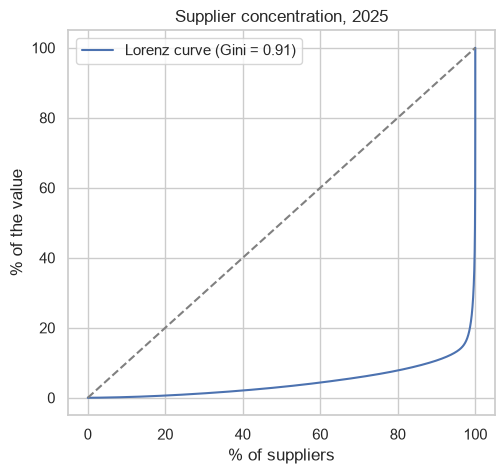

In [8]:
v = np.sort(prov["value"].values)
lorenz = np.concatenate([[0], np.cumsum(v) / v.sum()])
gini = 1 - 2 * np.trapezoid(lorenz, dx=1 / len(v))
desc = np.sort(prov["value"].values)[::-1]
print("Suppliers:", len(v))
print("Top 1% of suppliers, share of the value:", round(desc[:len(v) // 100].sum() / v.sum() * 100, 1), "%")
print("Gini:", round(gini, 3))

plt.figure(figsize=(5.5, 5))
plt.plot(np.linspace(0, 100, len(lorenz)), lorenz * 100, label=f"Lorenz curve (Gini = {gini:.2f})")
plt.plot([0, 100], [0, 100], ls="--", color="grey")
plt.title("Supplier concentration, 2025")
plt.xlabel("% of suppliers")
plt.ylabel("% of the value")
plt.legend()
plt.savefig("figures/supplier_lorenz.png", bbox_inches="tight")
plt.show()

In [9]:
pyme["es_pyme"] = pyme["es_pyme"].fillna("No")
p = pyme.pivot_table(index="year", columns="es_pyme", values="value", aggfunc="sum")
print("Share of the value for SMEs (%):")
print((p["Si"] / p.sum(axis=1) * 100).round(1).to_string())

Share of the value for SMEs (%):
year
2019    19.2
2020    15.5
2021    13.3
2022    22.3
2023    20.6
2024    24.3
2025    20.7
2026    22.2


## Conclusions

- The Colombian State signs around 1 million contracts per year in SECOP II. Around 80% of them are direct contracting, but they are only between 40% and 53% of the value.
- The Ley de Garantías changes the behaviour of the entities completely: a rush in January and almost no direct contracting until the elections. For insurers this is a predictable peak in the demand of surety policies (pólizas de cumplimiento) at the beginning of an election year.
- The money is very concentrated: the top 1% of the suppliers receive around three quarters of the value and SMEs only around 20%.